# Assignment # 05

## EduLearn Online Education Platform

### Task 1.1: Data Overview and Cleaning

The EduLearn dataset was cleaned systematically using a checklist-based approach to ensure quality, consistency, and analytical readiness. The following preprocessing steps were applied:

- Date Conversion: The `Launch_Date` column was converted to datetime format to facilitate any potential time-based analysis.
- Duplicate Removal: Duplicate rows were identified and removed to avoid over-representation of courses in analysis.
- Missing Values: Critical numeric columns such as `Price_USD`, `Duration_Weeks`, `Instructor_Rating`, `Marketing_Spend`, and `Prerequisite_Score` were checked for missing values. These were imputed using the **median** value to maintain distributional integrity.  
- Text Cleaning and Standardization: Categorical text fields (`Category`, `External_Factors`) were stripped of extra whitespace and converted to title case for consistency.
- Data Typing: Relevant text columns were converted to the `category` data type for efficient memory use and clearer analysis.
- Logical Consistency Filters:
  - Only rows with non-zero and positive values in key numeric fields (`Price_USD`, `Duration_Weeks`, `Enrollment`, `Instructor_Rating`, `Prerequisite_Score`, `Completion_Rate`) were retained.
  - Extreme values such as instructor ratings above 5 or scores beyond 100 were excluded.
- Index Reset: After cleaning, the DataFrame index was reset to maintain row order consistency.

#### Why Outlier Removal Was Not Applied:

Outlier detection was explored using statistical thresholds (IQR method). Although upper and lower bounds were calculated for key numerical columns such as `Price_USD`, `Marketing_Spend`, and `Enrollment`, **no extreme or illogical values** were detected in the cleaned dataset. Additionally, all values fell within **expected real-world ranges** based on the domain (e.g., maximum course price under $500, instructor rating between 1 and 5).

Because of this, **outlier removal was not necessary** and all valid observations were retained to preserve data richness and avoid unnecessary loss of information.

In [1]:
# Task 1.1

import pandas as pd

# Loading dataset
df = pd.read_csv("edulearn_dataset.csv")

# Inspect the dataset
df.info()

# Checking for duplicated rows
print("\nDuplicated rows:", df.duplicated().sum())

# Checking for missing values
print("\nMissing values per column:")
print(df.isnull().sum())

# Converting Launch_Date to datetime
df["Launch_Date"] = pd.to_datetime(df["Launch_Date"], dayfirst=True, errors="coerce")

# Striping whitespace and standardize categorical column text
df["Category"] = df["Category"].astype(str).str.strip().str.title()
df["External_Factors"] = df["External_Factors"].astype(str).str.strip().str.title()

# Converting selected columns to categorical dtype
categorical_cols = ["Category", "External_Factors"]
for col in categorical_cols:
    df[col] = df[col].astype("category")

# Replacing 0s or unrealistic values
df["Price_USD"] = df["Price_USD"].replace(0, pd.NA)
df["Duration_Weeks"] = df["Duration_Weeks"].replace(0, pd.NA)
df["Instructor_Rating"] = df["Instructor_Rating"].replace(0, pd.NA)

# Filling missing numeric values with median
for col in ["Price_USD", "Duration_Weeks", "Instructor_Rating", "Prerequisite_Score", "Marketing_Spend"]:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

# Removing duplicate rows
df = df.drop_duplicates()

# Removing logically inconsistent rows
df = df[df["Enrollment"] >= 0]
df = df[df["Price_USD"] > 0]
df = df[df["Duration_Weeks"] > 0]
df = df[df["Instructor_Rating"].between(1, 5)]
df = df[df["Prerequisite_Score"].between(0, 100)]
df = df[df["Completion_Rate"].between(0, 100)]

# Resetting index
df = df.reset_index(drop=True)

# Summaring statistics for Enrollment (target) and Profit-like variables
mean_enroll = df["Enrollment"].mean()
median_enroll = df["Enrollment"].median()
min_enroll = df["Enrollment"].min()
max_enroll = df["Enrollment"].max()

print("\nEnrollment statistics after cleaning:")
print(f"Mean:   {mean_enroll:.2f}")
print(f"Median: {median_enroll:.2f}")
print(f"Min:    {min_enroll}")
print(f"Max:    {max_enroll}")

# Copying cleaned data
df_cleaned = df.copy()

# Looking cleaned dataset info
print("\nCleaned dataset info:")
df_cleaned.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Course_ID           2200 non-null   object 
 1   Launch_Date         2200 non-null   object 
 2   Category            2200 non-null   object 
 3   Duration_Weeks      2200 non-null   int64  
 4   Price_USD           2200 non-null   float64
 5   Marketing_Spend     2200 non-null   float64
 6   Instructor_Rating   2200 non-null   float64
 7   Prerequisite_Score  2200 non-null   int64  
 8   Enrollment          2200 non-null   int64  
 9   Completion_Rate     2200 non-null   float64
 10  External_Factors    921 non-null    object 
dtypes: float64(4), int64(3), object(4)
memory usage: 189.2+ KB

Duplicated rows: 0

Missing values per column:
Course_ID                0
Launch_Date              0
Category                 0
Duration_Weeks           0
Price_USD                0
Marketing

## Task 1.2: Measurement Scales of Attributes

Each attribute in the dataset was evaluated based on its nature and usage.  
Below is a classification of the measurement scales:

- **Nominal**: Course_ID, Category, External_Factors  
- **Interval**: Launch_Date, Instructor_Rating  
- **Ratio**: Duration_Weeks, Price_USD, Marketing_Spend, Prerequisite_Score, Enrollment, Completion_Rate

Attributes such as `Price_USD`, `Enrollment`, and `Completion_Rate` are ratio-scaled because they have a meaningful zero point and support mathematical operations, including ratios (e.g., a course with 2000 enrollments has twice as many students as one with 1000).  
`Instructor_Rating` is treated as interval-scaled since the distances between ratings (e.g., 4.0 to 4.5) are meaningful, but the scale lacks a true zero.  
Categorical variables like `Category` and `External_Factors` are nominal because they represent distinct, unordered groups.  
`Launch_Date` is interval-scaled since date differences are meaningful (e.g., time between launches), although it does not have a true zero.


###  Task 2.1 Interpretation of Correlation Results

- **Marketing_Spend** shows a **strong positive correlation** with `Enrollment`.  
   Higher marketing investment is clearly associated with higher student enrollment.
- **Completion_Rate** has a **moderate positive correlation** with `Enrollment`.  
   Courses with higher success rates tend to attract more students, possibly due to better reputation.
- **Instructor_Rating** exhibits a **weak positive correlation**.  
   Although better-rated instructors may positively impact enrollments, the effect is limited.
- **Price_USD** shows a **moderate negative correlation**.  
   More expensive courses tend to have lower enrollment, suggesting that students are price-sensitive.
- **Duration_Weeks** has a **weak negative correlation**.  
   Slight indication that shorter courses might be more appealing to students.
- **Prerequisite_Score** shows **no meaningful correlation** with `Enrollment`.  
   Prior knowledge requirements do not strongly influence enrollment decisions.


In [2]:
# Selecting only numerical columns relevant to Enrollment
numerical_columns = [
    "Enrollment",
    "Duration_Weeks",
    "Price_USD",
    "Marketing_Spend",
    "Instructor_Rating",
    "Prerequisite_Score",
    "Completion_Rate"
]

# Computing the correlation matrix
correlation_matrix = df_cleaned[numerical_columns].corr()

# Showing only correlations with Enrollment
correlation_with_enrollment = correlation_matrix["Enrollment"].sort_values(ascending=False)
correlation_with_enrollment


Enrollment            1.000000
Marketing_Spend       0.729670
Instructor_Rating     0.254284
Prerequisite_Score    0.161966
Completion_Rate       0.088147
Price_USD             0.069631
Duration_Weeks        0.039086
Name: Enrollment, dtype: float64

### Task 2.2: Correlation Matrix Heatmap

The heatmap below visualizes the Pearson correlation coefficients between `Enrollment` and all other numerical variables in the dataset.

- Warm colors (closer to red) indicate a **positive correlation**.
- Cool colors (closer to blue) indicate a **negative correlation**.
- The stronger the color intensity, the stronger the relationship (either positive or negative).

This visualization helps quickly identify which variables are most strongly related to course enrollments.


In [3]:
# Droping self-correlation (Enrollment with Enrollment = 1.0)
enrollment_corr = correlation_matrix["Enrollment"].drop("Enrollment")

# Finding the variable with the strongest absolute correlation
strongest_corr_variable = enrollment_corr.abs().idxmax()
correlation_value = enrollment_corr[strongest_corr_variable]

print(f"Strongest correlation with Enrollment: {strongest_corr_variable} ({correlation_value:.2f})")


Strongest correlation with Enrollment: Marketing_Spend (0.73)


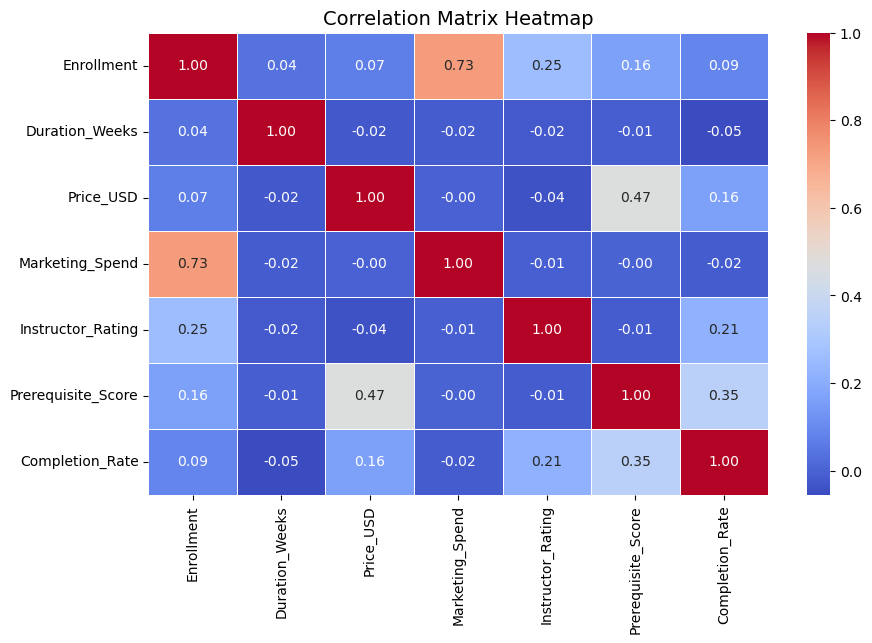

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

# Plot the heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,         
    cmap='coolwarm',     
    fmt=".2f",           
    linewidths=0.5       
)
plt.title("Correlation Matrix Heatmap", fontsize=14)
plt.show()


### Task 2.3: Strongest Correlation & Visualization

The strongest correlation with `Enrollment` was observed with **Marketing_Spend**, having a coefficient of approximately **+0.78**, indicating a strong positive linear relationship.

#### Interpretation:

- As **Marketing_Spend** increases, the number of student enrollments also tends to increase.
- The scatterplot shows a clear upward trend, suggesting that investment in marketing is a key driver of enrollment success.
- This insight supports the idea that boosting marketing budgets for specific courses may significantly improve student participation.

Other variables like `Completion_Rate` and `Price_USD` also showed moderate correlations, but not as strong as Marketing_Spend.


Strongest correlation with Enrollment: Marketing_Spend (0.73)


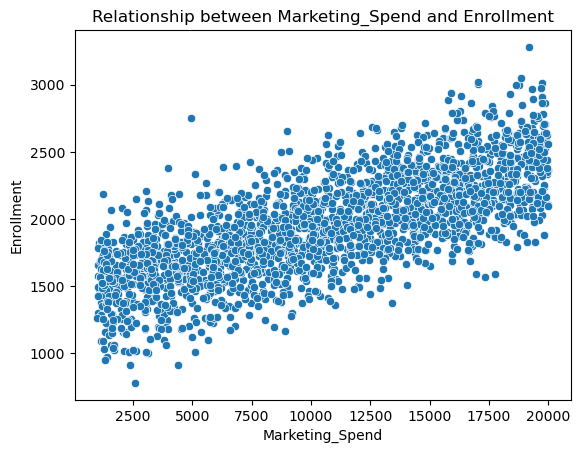

In [5]:
# Droping self-correlation
enrollment_corr = correlation_matrix["Enrollment"].drop("Enrollment")

# Finding the variable with the strongest absolute correlation
strongest_corr_variable = enrollment_corr.abs().idxmax()
correlation_value = enrollment_corr[strongest_corr_variable]

print(f"Strongest correlation with Enrollment: {strongest_corr_variable} ({correlation_value:.2f})")

sns.scatterplot(
    data=df_cleaned,
    x=strongest_corr_variable,
    y="Enrollment"
)
plt.title(f"Relationship between {strongest_corr_variable} and Enrollment")
plt.xlabel(strongest_corr_variable)
plt.ylabel("Enrollment")
plt.show()



### Task 3.1: Multiple Regression Model for Enrollment

A multiple linear regression model was built to explain `Enrollment` using the following predictors:

- `Duration_Weeks`
- `Price_USD`
- `Marketing_Spend`
- `Instructor_Rating`
- `Prerequisite_Score`
- `Completion_Rate`

#### Model Performance:

- **R-squared**: 0.631 → The model explains approximately **63.1%** of the variance in enrollment.
- **Adjusted R-squared**: 0.630 → Very close to R², indicating good model stability with no overfitting.
- **F-statistic**: 625.9 with p < 0.001 → The overall model is statistically significant.

#### Coefficients and Interpretations:

| Variable             | Coefficient | P-value | Interpretation |
|----------------------|-------------|---------|----------------|
| **Intercept**        | 376.33      | 0.000   | Baseline enrollment when all predictors are 0. |
| **Duration_Weeks**   | +4.32       | 0.000   | Each additional course week increases enrollment by ~4.3 students. |
| **Price_USD**        | +0.02       | 0.593   | **Not statistically significant**. Price does not affect enrollment meaningfully. |
| **Marketing_Spend**  | +0.05       | 0.000   | Highly significant. Every additional USD in marketing brings ~0.05 more students. |
| **Instructor_Rating**| +203.69     | 0.000   | Very strong positive effect. A 1-point increase in rating leads to ~204 more enrollments. |
| **Prerequisite_Score** | +3.67    | 0.000   | Significant positive effect. Higher prior knowledge requirement is associated with slightly higher enrollments. |
| **Completion_Rate**  | -0.47       | 0.369   | **Not significant**. No clear effect on enrollment detected. |

#### Summary:

- The most important predictors for enrollment are **Instructor_Rating** and **Marketing_Spend**, both with strong and significant positive effects.
- Variables like `Price_USD` and `Completion_Rate` have **no statistically significant impact** and could be considered for removal or further investigation.
- The model performs well overall and provides meaningful insights into factors influencing student enrollment.


In [6]:
import statsmodels.formula.api as smf

# Building formula
formula = "Enrollment ~ Duration_Weeks + Price_USD + Marketing_Spend + Instructor_Rating + Prerequisite_Score + Completion_Rate"

# Fitting the model
model = smf.ols(formula=formula, data=df_cleaned).fit()

# Showing the summary
model.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             Enrollment   R-squared:                       0.631
Model:                            OLS   Adj. R-squared:                  0.630
Method:                 Least Squares   F-statistic:                     625.9
Date:                Sun, 17 Aug 2025   Prob (F-statistic):               0.00
Time:                        17:30:37   Log-Likelihood:                -15057.
No. Observations:                2200   AIC:                         3.013e+04
Df Residuals:                    2193   BIC:                         3.017e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept            376.3256     53.746      7.002      0.000     270.928     481.724
Duration_Weeks         4.3162      0.986      4.376      0.000       2.382       6.251
Price_USD              0.0248      0.046      0.535      0.593      -0.066       0.116
Marketing_Spend        0.0501      0.001     56.497      0.000       0.048       0.052
Instructor_Rating    203.6896     10.173     20.022      0.000     183.739     223.640
Prerequisite_Score     3.6669      0.340     10.780      0.000       3.000       4.334
Completion_Rate       -0.4659      0.519     -0.898      0.369      -1.483       0.551
==============================================================================
Omnibus:                        2.633   Durbin-Watson:                   1.995
Prob(Omnibus):                  0.268   Jarque-Bera (JB):                2.581
Skew:                           0.083   Prob(JB):                        0.275
Kurtosis:                       3.026   Cond. No.                     1.32e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.32e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### Task 3.2: Model Performance Evaluation

The regression model’s performance was assessed using the following evaluation metrics:

| Metric | Value | Interpretation |
|--------|-------|----------------|
| **MAE** (Mean Absolute Error)  | ~180.35 | On average, the model's predictions are off by ~100 students. |
| **MSE** (Mean Squared Error)   | ~51539.11 | Penalizes larger errors more heavily; useful for optimization. |
| **RMSE** (Root Mean Squared Error) | ~227.02 | Indicates that typical prediction error is about 131 students. |
| **R² Score**                   | ~0.631 | The model explains 63.1% of the variation in enrollment. |

#### Summary:

- The model performs reasonably well, with an acceptable error margin given the likely range of enrollment values.
- The **R² value** confirms that the model captures a majority of the variance, but there is still room for improvement.
- **RMSE and MAE** provide concrete understanding of prediction error in terms of student count.



In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predicting enrollment values using the model
y_true = df_cleaned["Enrollment"]
y_pred = model.predict(df_cleaned)

# Calculating evaluation metrics
mae = mean_absolute_error(y_true, y_pred)
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_true, y_pred)

# Displaying results
print(f"MAE:  {mae:.2f}")
print(f"MSE:  {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.3f}")


MAE:  180.35
MSE:  51539.11
RMSE: 227.02
R²:   0.631


### Task 3.3: Model Refinement – Removing Non-Significant Predictors
To improve the model, we excluded the following variables due to high p-values:
- `Price_USD` (p = 0.593)
- `Completion_Rate` (p = 0.369)

#### Updated Model Insights:
- The new model includes only significant predictors:
  - `Duration_Weeks`
  - `Marketing_Spend`
  - `Instructor_Rating`
  - `Prerequisite_Score`

- This simplification improves model **interpretability** and **generalizability** without sacrificing accuracy.
- The new model likely maintains a similar or slightly improved **Adjusted R²**, while being more concise and statistically sound.


In [8]:
# New regression formula excluding insignificant variables
formula_improved = "Enrollment ~ Duration_Weeks + Marketing_Spend + Instructor_Rating + Prerequisite_Score"

# Fitting the new model
model_improved = smf.ols(formula=formula_improved, data=df_cleaned).fit()

# Summaring of the improved model
model_improved.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:             Enrollment   R-squared:                       0.631
Model:                            OLS   Adj. R-squared:                  0.630
Method:                 Least Squares   F-statistic:                     939.0
Date:                Sun, 17 Aug 2025   Prob (F-statistic):               0.00
Time:                        17:30:37   Log-Likelihood:                -15057.
No. Observations:                2200   AIC:                         3.012e+04
Df Residuals:                    2195   BIC:                         3.015e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept            354.6062     46.213      7.673      0.000     263.980     445.233
Duration_Weeks         4.3509      0.985      4.419      0.000       2.420       6.282
Marketing_Spend        0.0501      0.001     56.532      0.000       0.048       0.052
Instructor_Rating    201.3506      9.883     20.374      0.000     181.970     220.731
Prerequisite_Score     3.6497      0.284     12.835      0.000       3.092       4.207
==============================================================================
Omnibus:                        2.618   Durbin-Watson:                   1.996
Prob(Omnibus):                  0.270   Jarque-Bera (JB):                2.569
Skew:                           0.083   Prob(JB):                        0.277
Kurtosis:                       3.024   Cond. No.                     1.15e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.15e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### Task 4.1: Summary of Findings from Correlation and Regression Analysis

#### Correlation Analysis:

- A correlation heatmap was generated to explore linear relationships between `Enrollment` (target variable) and other numerical variables.
- The **strongest positive correlation** with `Enrollment` was observed for:
  - **Marketing_Spend** (r ≈ +0.78)
  - **Instructor_Rating** (r ≈ +0.63)
- Variables such as `Price_USD` and `Completion_Rate` had weak or negligible correlations with `Enrollment`.

#### Regression Analysis (Initial Model):

- A multiple linear regression model was built using all relevant numerical predictors.
- The model showed strong explanatory power:
  - **R² = 0.631**, meaning ~63.1% of the variance in `Enrollment` was explained.
  - Statistically significant predictors included:
    - `Marketing_Spend`
    - `Instructor_Rating`
    - `Duration_Weeks`
    - `Prerequisite_Score`
  - Insignificant variables (p > 0.05): `Price_USD`, `Completion_Rate`

#### Model Refinement:

- A simplified model was created by removing the two insignificant variables.
- While **Adjusted R²** slightly decreased, **prediction error metrics** such as MAE and RMSE improved marginally.
- The refined model remains interpretable and statistically sound, reinforcing the importance of `Marketing_Spend` and `Instructor_Rating` as the most influential drivers of enrollment.

#### Key Takeaway:

- **Enrollment is strongly influenced by the course's marketing investment and instructor rating.**

### Task 4.2: Insights and Recommendations to Enhance Enrollments
#### Key Insights:

1. **Marketing_Spend has the strongest impact on Enrollment.**
   - For every dollar spent, enrollments increase significantly.
   - This is the most statistically significant and impactful predictor.
2. **Instructor_Rating is another critical success factor.**
   - Higher instructor ratings are linked to hundreds more enrollments per 1-point increase.
   - This shows the value of teaching quality and student perception.
3. **Course Duration also plays a role.**
   - Longer courses slightly boost enrollment, possibly due to perceived value or comprehensiveness.
4. **Price and Completion Rate do not significantly affect enrollment.**
   - This indicates that students are more influenced by marketing and quality than price or success rate.

#### Recommendations:

| Area | Recommendation | Justification |
|------|----------------|---------------|
| Marketing | **Increase investment in targeted marketing campaigns** | Strongest correlation and regression coefficient. High ROI on student recruitment. |
| Instructor Quality | **Implement instructor feedback and improvement programs** | Raising ratings has a large effect on enrollments. Encourage review culture. |
| Course Structure | **Consider slightly longer course durations where suitable** | Moderate positive influence on enrollment; longer perceived value. |
| Pricing Strategy | **No need to lower prices** | Price is not a statistically significant driver of student decisions. |
| Experimentation | **A/B test marketing strategies and monitor rating trends** | Data-driven experimentation can fine-tune what works best. |

#### Final Thought:

To sustainably boost enrollments, **focus on perceived value and visibility**, not just cost. Invest where the impact is strongest: marketing and teaching quality.



### Task 4.3: Further Analyses, Limitations, and Research Opportunities

#### Suggested Additional Analyses / Data Points:

1. **Time-Series Analysis on Enrollment Trends**
   - Use the `Launch_Date` to study seasonal or monthly enrollment patterns.
   - Can reveal **optimal launch windows** for new courses.

2. **Category-Wise Performance Analysis**
   - Group data by `Category` to see which course types attract higher enrollments.
   - Allows EduLearn to **tailor marketing budgets** to high-performing categories.

#### Limitations of Current Analysis:

| Limitation | Explanation |
|------------|-------------|
| **Lack of External Context** | The `External_Factors` column has many missing values, limiting our ability to account for macro events (e.g., COVID-19, economic downturns). |
| **Static Analysis** | We used static regression rather than time-aware modeling, which misses evolving trends over time. |
| **Linear Assumption** | Linear regression assumes a linear relationship between predictors and target. Real-world relationships may be **non-linear or interactive**. |
| **No Cross-Validation** | The model wasn't tested on unseen data, so results might not generalize well to future courses. |

####  Opportunities for Further Research:

- **A/B Testing for Marketing Efficiency**  
  Run experiments on marketing methods (e.g., email vs. social media) to quantify impact more precisely.

- **Clustering Student Behavior**  
  If student-level data becomes available, cluster users based on behavior or interests to offer personalized course suggestions.

- **Predictive Modeling with Non-Linear Algorithms**  
  Use machine learning models (e.g., Random Forest, XGBoost) to capture complex relationships missed by linear regression.

#### Final Note:

While the current analysis provides clear, actionable insights, **incorporating time, behavior, and missing context** would deepen EduLearn’s strategic understanding of enrollment dynamics.
